# CIFAR-10: dataset exploration

Load the dataset, inspect sample images per class, and check the class
balance. The notebook resolves `data/` relative to the repository
root, the project root, or this `notebooks/` directory, so it can be run
from any of those places. The dataset must already be downloaded (see
`scripts/download_data.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torchvision

# `data/` lives next to `notebooks/` (the project root), but the kernel's
# working directory varies by environment, so try the plausible candidate
# locations and fail fast instead of downloading (scripts/download_data.py
# owns the download).
DATA_DIR = next(
    (
        p
        for p in (
            Path("data"),
            Path("..") / "data",
            Path("projects/cifar10-cnn/data"),
        )
        if (p / "cifar-10-batches-py").is_dir()
    ),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "CIFAR-10 data not found; run scripts/download_data.py first."
    )
train_ds = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=False)
test_ds = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=False)
print(f"{len(train_ds):,} train | {len(test_ds):,} test")
print(train_ds.classes)

50,000 train | 10,000 test
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


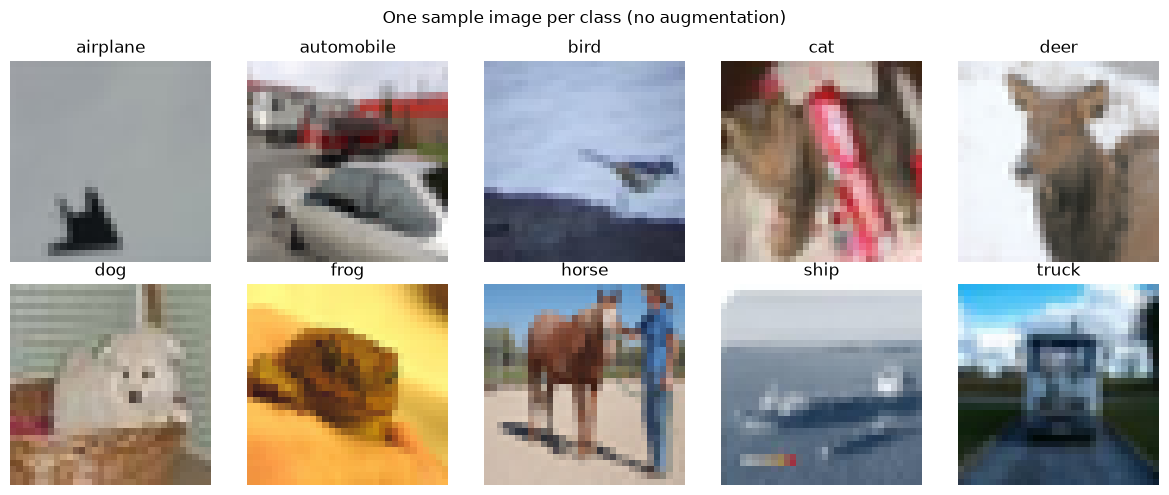

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, class_idx in zip(axes.ravel(), range(10), strict=True):
    for i in range(len(train_ds) - 1, -1, -1):
        image, label = train_ds[i]
        if label == class_idx:
            ax.imshow(image)
            break
    ax.set_title(train_ds.classes[class_idx])
    ax.axis("off")
plt.suptitle("One sample image per class (no augmentation)")
plt.tight_layout()
plt.show()

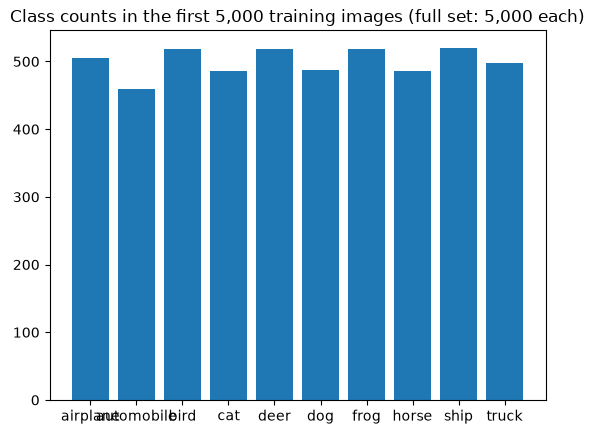

In [3]:
import numpy as np

sample_size = 5_000
labels = np.array([train_ds[i][1] for i in range(sample_size)])
counts = np.bincount(labels, minlength=10)
plt.bar(train_ds.classes, counts)
plt.title(
    f"Class counts in the first {sample_size:,} training images (full set: 5,000 each)"
)
plt.show()